# FraudShield: training pipeline (two datasets, two specialist models)

| Key | Dataset | Files expected in `./data/` |
|---|---|---|
| `paysim` | PaySim mobile-money transactions | `paysim_dataset.csv` |
| `sparkov` | Sparkov simulated card transactions | `fraudTrain.csv`, `fraudTest.csv` |

For each dataset the same protocol runs: baseline (Logistic Regression) -> Random Forest -> XGBoost -> tuned RF and XGBoost
(`RandomizedSearchCV`, PR-AUC). Models are fitted on a training split, **selected on a validation split**, and scored **once on a held-out test set**.
The decision threshold is chosen on validation (max F1). The best model per dataset is saved to `models/`.

In [1]:
import json, os, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_DIR = Path(os.environ.get("FS_DATA_DIR", "./data"))

# models/ lives at the project root (index.py loads ROOT_DIR / "models" / ...)
ROOT = Path.cwd()
if not (ROOT / "models").exists() and (ROOT.parent / "models").exists():
    ROOT = ROOT.parent
MODELS_DIR = Path(os.environ.get("FS_MODELS_DIR", ROOT / "models"))
REPORTS_DIR = MODELS_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

TUNE_ROWS = int(os.environ.get("FS_TUNE_ROWS", 300_000))  # rows used inside the hyper-parameter search
N_ITER = int(os.environ.get("FS_N_ITER", 6))              # random-search candidates per model
CV_FOLDS = 3

print("data  :", DATA_DIR.resolve())
print("models:", MODELS_DIR.resolve())

data  : C:\Users\muham\Desktop\Stuff\Programs\fraudshield\data
models: C:\Users\muham\Desktop\Stuff\Programs\fraudshield\models


## Shared helpers

In [2]:
def make_pre(cat, num):
    parts = []
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    parts.append(("num", StandardScaler(), num))
    return ColumnTransformer(parts)


def base_models(neg, pos):
    return {
        "Logistic Regression (baseline)": LogisticRegression(
            class_weight="balanced", max_iter=1000),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=12, class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.1,
            scale_pos_weight=neg / pos, tree_method="hist",
            eval_metric="aucpr", n_jobs=-1, random_state=SEED),
    }


SEARCH_SPACES = {
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [8, 12, 16, 20],
        "min_samples_leaf": [1, 2, 5],
        "max_features": ["sqrt", 0.5],
    },
    "XGBoost": {
        "n_estimators": [200, 300, 500],
        "max_depth": [4, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1, 0.2],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0],
        "min_child_weight": [1, 3, 5],
    },
}


def tune(name, base_clf, cat, num, X_fit, y_fit):
    """Random search scored by PR-AUC on a stratified subsample of the training split."""
    if len(X_fit) > TUNE_ROWS:
        X_s, _, y_s, _ = train_test_split(
            X_fit, y_fit, train_size=TUNE_ROWS, stratify=y_fit, random_state=SEED)
    else:
        X_s, y_s = X_fit, y_fit
    pipe = Pipeline([("pre", make_pre(cat, num)), ("model", clone(base_clf))])
    space = {f"model__{k}": v for k, v in SEARCH_SPACES[name].items()}
    search = RandomizedSearchCV(
        pipe, space, n_iter=N_ITER, scoring="average_precision",
        cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED),
        random_state=SEED, n_jobs=1, refit=False)
    search.fit(X_s, y_s)
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"  tuned {name}: CV PR-AUC={search.best_score_:.4f}  params={best}")
    return clone(base_clf).set_params(**best), best


def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


def score(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
    }


def feature_importance(pipe):
    names = pipe.named_steps["pre"].get_feature_names_out()
    m = pipe.named_steps["model"]
    vals = getattr(m, "feature_importances_", None)
    if vals is None:
        vals = np.abs(m.coef_[0])
    return (pd.DataFrame({"feature": names, "importance": vals})
            .sort_values("importance", ascending=False).reset_index(drop=True))


def group_audit(y_true, pred, groups):
    """Per-group flag rate, recall and false-positive rate (fairness audit)."""
    df = pd.DataFrame({"y": np.asarray(y_true), "pred": np.asarray(pred), "g": np.asarray(groups)})
    rows = []
    for g, d in df.groupby("g", observed=True):
        neg, pos = (d.y == 0).sum(), (d.y == 1).sum()
        rows.append({
            "group": g, "n": len(d), "fraud_rate": d.y.mean(),
            "flag_rate": d.pred.mean(),
            "recall": ((d.pred == 1) & (d.y == 1)).sum() / pos if pos else np.nan,
            "false_positive_rate": ((d.pred == 1) & (d.y == 0)).sum() / neg if neg else np.nan,
        })
    return pd.DataFrame(rows)

In [3]:
def run_experiment(key, d):
    cat, num = d["cat"], d["num"]
    X_fit, y_fit = d["X_fit"], d["y_fit"]
    X_val, y_val = d["X_val"], d["y_val"]
    X_test, y_test = d["X_test"], d["y_test"]
    neg, pos = int((y_fit == 0).sum()), int((y_fit == 1).sum())
    print(f"\n=== {key}: fit={len(X_fit):,} (fraud {pos:,})  val={len(X_val):,}  test={len(X_test):,} ===")

    models = base_models(neg, pos)
    tuned_params = {}
    for name in ("Random Forest", "XGBoost"):
        print(f"Tuning {name} ...")
        clf, tuned_params[name] = tune(name, models[name], cat, num, X_fit, y_fit)
        models[f"{name} (tuned)"] = clf

    rows, fitted, test_proba, thresholds = [], {}, {}, {}
    for name, clf in models.items():
        t0 = time.time()
        pipe = Pipeline([("pre", make_pre(cat, num)), ("model", clf)]).fit(X_fit, y_fit)
        pv = pipe.predict_proba(X_val)[:, 1]
        pt = pipe.predict_proba(X_test)[:, 1]
        thr = best_f1_threshold(y_val, pv)
        s05, sthr = score(y_test, pt, 0.5), score(y_test, pt, thr)
        rows.append({
            "Dataset": key, "Model": name,
            "Val PR-AUC": average_precision_score(y_val, pv),
            "Precision@0.5": s05["precision"], "Recall@0.5": s05["recall"], "F1@0.5": s05["f1"],
            "Threshold": thr,
            "Precision@thr": sthr["precision"], "Recall@thr": sthr["recall"], "F1@thr": sthr["f1"],
            "ROC-AUC": roc_auc_score(y_test, pt),
            "PR-AUC": average_precision_score(y_test, pt),
            "Fit seconds": time.time() - t0,
        })
        fitted[name], test_proba[name], thresholds[name] = pipe, pt, thr
        print(f"  {name:<32} val PR-AUC={rows[-1]['Val PR-AUC']:.4f}  test PR-AUC={rows[-1]['PR-AUC']:.4f}  ({time.time()-t0:.0f}s)")

    comparison = pd.DataFrame(rows).round(4)
    # model selection uses VALIDATION PR-AUC only; the test set is never used to choose
    best = comparison.sort_values("Val PR-AUC", ascending=False).iloc[0]["Model"]
    pipe, thr, pt = fitted[best], thresholds[best], test_proba[best]
    pred = (pt >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"\nSelected for {key}: {best}  (threshold {thr:.4f})  TP={tp} FP={fp} FN={fn} TN={tn}")

    # ---- artifacts ----
    model_path = MODELS_DIR / f"fraudshield_{key}.joblib"
    joblib.dump(pipe, model_path)
    feature_importance(pipe).to_csv(REPORTS_DIR / f"feature_importance_{key}.csv", index=False)
    comparison.to_csv(REPORTS_DIR / f"model_comparison_{key}.csv", index=False)

    best_row = comparison[comparison.Model == best].iloc[0]
    meta = {
        "dataset": key, "model": best, "threshold": thr,
        "categorical_features": cat, "numeric_features": num,
        "rows": {"fit": len(X_fit), "val": len(X_val), "test": len(X_test)},
        "test_metrics_at_threshold": {
            "precision": float(best_row["Precision@thr"]), "recall": float(best_row["Recall@thr"]),
            "f1": float(best_row["F1@thr"]), "roc_auc": float(best_row["ROC-AUC"]),
            "pr_auc": float(best_row["PR-AUC"])},
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
        "tuned_params": {k: {a: (b.item() if hasattr(b, "item") else b) for a, b in v.items()}
                         for k, v in tuned_params.items()},
        "sklearn_version": sklearn.__version__,
        "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    }
    (MODELS_DIR / f"fraudshield_{key}_metadata.json").write_text(json.dumps(meta, indent=2))

    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, p in test_proba.items():
        pr, rc, _ = precision_recall_curve(y_test, p)
        ax.plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
    ax.set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall, {key} test set")
    ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(REPORTS_DIR / f"pr_curves_{key}.png", dpi=150); plt.show()

    print(f"Saved {model_path}")
    return {"comparison": comparison, "best": best, "pipe": pipe, "thr": thr, "pred": pred}

## Dataset loaders

**PaySim** keeps the original feature set (type, amount, balances, plus the two balance-error features). Identifiers (`nameOrig`, `nameDest`), `step`
and `isFlaggedFraud` are dropped. Random stratified 80/20 train/test split.

**Sparkov** uses the dataset's own chronological train/test files (so the test set is *later in time*, which is closer to real deployment).
Names, card numbers, street addresses, job and merchant names are never used (privacy). Features are engineered from time, age and the
customer-to-merchant distance. `gender` is **excluded from the model** and kept only for the fairness audit.

In [4]:
def load_paysim():
    df = pd.read_csv(DATA_DIR / "paysim_dataset.csv")
    print("PaySim", df.shape, "| missing values:", int(df.isnull().sum().sum()),
          "| fraud rate: %.4f%%" % (100 * df["isFraud"].mean()))
    df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
    df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
    cat = ["type"]
    num = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest",
           "newbalanceDest", "errorBalanceOrig", "errorBalanceDest"]
    X, y = df[cat + num], df["isFraud"]
    X_tv, X_test, y_tv, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED)
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_tv, y_tv, test_size=0.2, stratify=y_tv, random_state=SEED)
    return dict(cat=cat, num=num, X_fit=X_fit, y_fit=y_fit, X_val=X_val, y_val=y_val,
                X_test=X_test, y_test=y_test)


SPARKOV_COLS = ["trans_date_trans_time", "category", "gender", "amt", "city_pop", "dob",
                "lat", "long", "merch_lat", "merch_long", "is_fraud"]


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def sparkov_features(df):
    ts = pd.to_datetime(df["trans_date_trans_time"])
    dob = pd.to_datetime(df["dob"])
    X = pd.DataFrame({
        "category": df["category"].astype(str),
        "amt": df["amt"], "city_pop": df["city_pop"],
        "hour": ts.dt.hour, "day_of_week": ts.dt.dayofweek,
        "age": (ts - dob).dt.days / 365.25,
        "distance_km": haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"]),
    })
    return X, df["is_fraud"].astype(int), df["gender"].astype(str)


def load_sparkov():
    train = pd.read_csv(DATA_DIR / "fraudTrain.csv", usecols=SPARKOV_COLS)
    test = pd.read_csv(DATA_DIR / "fraudTest.csv", usecols=SPARKOV_COLS)
    print("Sparkov train", train.shape, "test", test.shape, "| missing values:",
          int(train.isnull().sum().sum() + test.isnull().sum().sum()),
          "| fraud rate (train): %.4f%%" % (100 * train["is_fraud"].mean()))
    train = train.sort_values("trans_date_trans_time").reset_index(drop=True)
    X_tv, y_tv, _ = sparkov_features(train)
    X_test, y_test, g_test = sparkov_features(test)
    cat = ["category"]
    num = ["amt", "city_pop", "hour", "day_of_week", "age", "distance_km"]
    cut = int(len(X_tv) * 0.8)  # validation = the most recent 20% of the training file
    return dict(cat=cat, num=num,
                X_fit=X_tv.iloc[:cut], y_fit=y_tv.iloc[:cut],
                X_val=X_tv.iloc[cut:], y_val=y_tv.iloc[cut:],
                X_test=X_test[cat + num], y_test=y_test, gender_test=g_test)

## Train: PaySim

PaySim (6362620, 11) | missing values: 0 | fraud rate: 0.1291%

=== paysim: fit=4,072,076 (fraud 5,256)  val=1,018,020  test=1,272,524 ===
Tuning Random Forest ...
  tuned Random Forest: CV PR-AUC=0.9896  params={'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}
Tuning XGBoost ...
  tuned XGBoost: CV PR-AUC=0.9854  params={'subsample': 0.85, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
  Logistic Regression (baseline)   val PR-AUC=0.5556  test PR-AUC=0.5615  (14s)
  Random Forest                    val PR-AUC=0.9998  test PR-AUC=0.9987  (274s)
  XGBoost                          val PR-AUC=0.9989  test PR-AUC=0.9973  (66s)
  Random Forest (tuned)            val PR-AUC=1.0000  test PR-AUC=0.9982  (742s)
  XGBoost (tuned)                  val PR-AUC=0.9970  test PR-AUC=0.9976  (99s)

Selected for paysim: Random Forest (tuned)  (threshold 0.7394)  TP=1639 FP=0 FN=4 TN=1270881


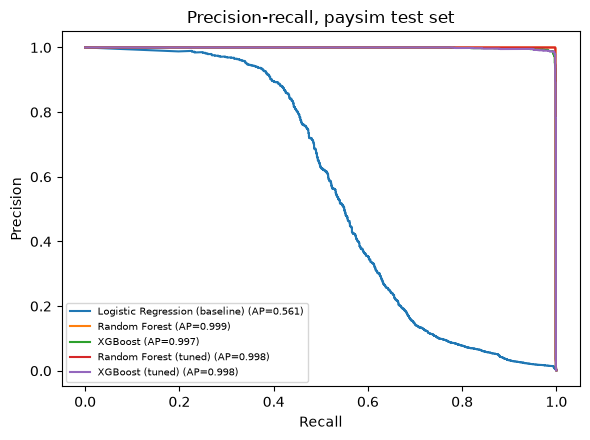

Saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\models\fraudshield_paysim.joblib
                         Model  Val PR-AUC  Precision@0.5  Recall@0.5  F1@0.5  Threshold  Precision@thr  Recall@thr  F1@thr  ROC-AUC  PR-AUC  Fit seconds
Logistic Regression (baseline)      0.5556         0.0228      0.9385  0.0445     0.9999         0.7607      0.4644  0.5767   0.9900  0.5615      13.5715
                 Random Forest      0.9998         0.9994      0.9970  0.9982     0.7690         1.0000      0.9939  0.9969   0.9995  0.9987     274.2242
                       XGBoost      0.9989         0.9669      0.9963  0.9814     0.9954         0.9879      0.9915  0.9897   0.9996  0.9973      66.1870
         Random Forest (tuned)      1.0000         1.0000      0.9976  0.9988     0.7394         1.0000      0.9976  0.9988   0.9995  0.9982     741.6431
               XGBoost (tuned)      0.9970         0.9151      0.9976  0.9546     0.9937         0.9855      0.9957  0.9906   0.9996  0.9976 

In [5]:
paysim = load_paysim()
res_paysim = run_experiment("paysim", paysim)
print(res_paysim["comparison"].drop(columns=["Dataset"]).to_string(index=False))

## Train: Sparkov

Sparkov train (1296675, 11) test (555719, 11) | missing values: 0 | fraud rate (train): 0.5789%

=== sparkov: fit=1,037,340 (fraud 5,968)  val=259,335  test=555,719 ===
Tuning Random Forest ...
  tuned Random Forest: CV PR-AUC=0.8835  params={'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}
Tuning XGBoost ...
  tuned XGBoost: CV PR-AUC=0.9023  params={'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
  Logistic Regression (baseline)   val PR-AUC=0.1685  test PR-AUC=0.1178  (4s)
  Random Forest                    val PR-AUC=0.8612  test PR-AUC=0.8110  (73s)
  XGBoost                          val PR-AUC=0.8950  test PR-AUC=0.8509  (16s)
  Random Forest (tuned)            val PR-AUC=0.9040  test PR-AUC=0.8598  (229s)
  XGBoost (tuned)                  val PR-AUC=0.8938  test PR-AUC=0.8542  (16s)

Selected for sparkov: Random Forest (tuned)  (threshold 0.7749)  TP=1635 FP=244 FN=5

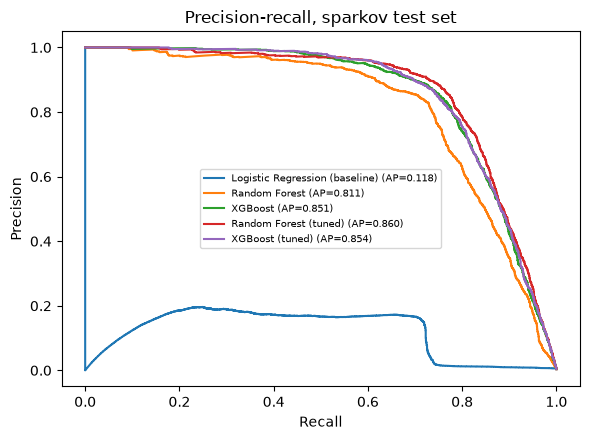

Saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\models\fraudshield_sparkov.joblib
                         Model  Val PR-AUC  Precision@0.5  Recall@0.5  F1@0.5  Threshold  Precision@thr  Recall@thr  F1@thr  ROC-AUC  PR-AUC  Fit seconds
Logistic Regression (baseline)      0.1685         0.0234      0.7399  0.0453     0.7816         0.1691      0.6793  0.2708   0.9056  0.1178       3.6554
                 Random Forest      0.8612         0.2413      0.9324  0.3833     0.8417         0.8074      0.7347  0.7693   0.9942  0.8110      73.3289
                       XGBoost      0.8950         0.3049      0.9277  0.4589     0.9720         0.8338      0.7646  0.7977   0.9964  0.8509      16.3270
         Random Forest (tuned)      0.9040         0.5475      0.8732  0.6730     0.7749         0.8701      0.7622  0.8126   0.9967  0.8598     228.9756
               XGBoost (tuned)      0.8938         0.2985      0.9301  0.4519     0.9730         0.8310      0.7590  0.7934   0.9965  0.8542

In [6]:
sparkov = load_sparkov()
res_sparkov = run_experiment("sparkov", sparkov)
print(res_sparkov["comparison"].drop(columns=["Dataset"]).to_string(index=False))

## Combined results and fairness audit

In [7]:
all_results = pd.concat([res_paysim["comparison"], res_sparkov["comparison"]], ignore_index=True)
all_results.to_csv(MODELS_DIR / "model_comparison.csv", index=False)
print(all_results[["Dataset", "Model", "Val PR-AUC", "Precision@thr", "Recall@thr", "F1@thr", "ROC-AUC", "PR-AUC"]]
      .to_string(index=False))

# Fairness audit on the Sparkov test set (gender was NOT a model input)
audit_df = group_audit(sparkov["y_test"], res_sparkov["pred"], sparkov["gender_test"])
audit_df.round(5).to_csv(REPORTS_DIR / "fairness_audit_sparkov_gender.csv", index=False)
print("\nFairness audit (Sparkov, by gender):")
print(audit_df.round(5).to_string(index=False))

Dataset                          Model  Val PR-AUC  Precision@thr  Recall@thr  F1@thr  ROC-AUC  PR-AUC
 paysim Logistic Regression (baseline)      0.5556         0.7607      0.4644  0.5767   0.9900  0.5615
 paysim                  Random Forest      0.9998         1.0000      0.9939  0.9969   0.9995  0.9987
 paysim                        XGBoost      0.9989         0.9879      0.9915  0.9897   0.9996  0.9973
 paysim          Random Forest (tuned)      1.0000         1.0000      0.9976  0.9988   0.9995  0.9982
 paysim                XGBoost (tuned)      0.9970         0.9855      0.9957  0.9906   0.9996  0.9976
sparkov Logistic Regression (baseline)      0.1685         0.1691      0.6793  0.2708   0.9056  0.1178
sparkov                  Random Forest      0.8612         0.8074      0.7347  0.7693   0.9942  0.8110
sparkov                        XGBoost      0.8950         0.8338      0.7646  0.7977   0.9964  0.8509
sparkov          Random Forest (tuned)      0.9040         0.8701      0.

## Sanity check: reload saved models and score one transaction each

In [8]:
meta = {k: json.loads((MODELS_DIR / f"fraudshield_{k}_metadata.json").read_text()) for k in ("paysim", "sparkov")}

ps = pd.DataFrame([{"type": "TRANSFER", "amount": 181.0, "oldbalanceOrg": 181.0, "newbalanceOrig": 0.0,
                    "oldbalanceDest": 0.0, "newbalanceDest": 0.0}])
ps["errorBalanceOrig"] = ps["newbalanceOrig"] + ps["amount"] - ps["oldbalanceOrg"]
ps["errorBalanceDest"] = ps["oldbalanceDest"] + ps["amount"] - ps["newbalanceDest"]
m = joblib.load(MODELS_DIR / "fraudshield_paysim.joblib")
p = m.predict_proba(ps[paysim["cat"] + paysim["num"]])[0, 1]
print("PaySim  fraud probability:", round(float(p), 4), "-> flagged:", p >= meta["paysim"]["threshold"])

sp = pd.DataFrame([{"category": "shopping_net", "amt": 912.5, "city_pop": 1200, "hour": 2,
                    "day_of_week": 5, "age": 34.0, "distance_km": 88.0}])
m = joblib.load(MODELS_DIR / "fraudshield_sparkov.joblib")
p = m.predict_proba(sp[sparkov["cat"] + sparkov["num"]])[0, 1]
print("Sparkov fraud probability:", round(float(p), 4), "-> flagged:", p >= meta["sparkov"]["threshold"])
print("\nFiles in models/:", sorted(x.name for x in MODELS_DIR.iterdir()))

PaySim  fraud probability: 0.9999 -> flagged: True
Sparkov fraud probability: 0.9735 -> flagged: True

Files in models/: ['fraudshield_model.joblib', 'fraudshield_paysim.joblib', 'fraudshield_paysim_metadata.json', 'fraudshield_sparkov.joblib', 'fraudshield_sparkov_metadata.json', 'model_comparison.csv', 'reports']
